In [34]:
from astropy.io import fits
import pandas as pd
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt

from GalVel_Pop import gal_population, UVW

In [35]:
gaia_for_galah_dat = Table.read('galah_dr4_vac_wise_tmass_gaiadr3_240705.fits', format='fits')
names_gaia_for_galah = [name for name in gaia_for_galah_dat.colnames if len(gaia_for_galah_dat[name].shape) <= 1]
gaia_for_galah_df = gaia_for_galah_dat[names_gaia_for_galah].to_pandas()

In [36]:
gaia_for_galah_df_columns = ['sobject_id', 
                             'ra', 'ra_error', 'dec', 'dec_error', 
                            'parallax', 'parallax_error',
                            'pmra', 'pmra_error', 
                            'pmdec', 'pmdec_error',
                            'phot_g_mean_mag',
                            'phot_bp_mean_mag', 'phot_rp_mean_mag',
                            'radial_velocity', 'radial_velocity_error',
                            'r_med_geo', 'r_med_photogeo',]

gaia_for_galah_df = gaia_for_galah_df[gaia_for_galah_df_columns]

In [37]:
galah_dat = Table.read('galah_dr4_allstar_240705.fits', format='fits')
names_galah = [name for name in galah_dat.colnames if len(galah_dat[name].shape) <= 1]
galah_df = galah_dat[names_galah].to_pandas()
galah_df_copy = galah_df.copy()

In [38]:
gaia_df_columns = ['sobject_id', 'gaiadr3_source_id',
                    'rv_comp_1', 'e_rv_comp_1', 'rv_gaia_dr3', 'e_rv_gaia_dr3',
                    'snr_px_ccd2', 'flag_sp', 
                    'teff', 'e_teff',
                    'logg', 'e_logg', 
                    'fe_h', 'e_fe_h', 'flag_fe_h',
                    'c_fe', 'e_c_fe', 'flag_c_fe',
                    'o_fe', 'e_o_fe', 'flag_o_fe',
                    'mg_fe', 'e_mg_fe', 'flag_mg_fe',
                    'si_fe', 'e_si_fe', 'flag_si_fe',
]

galah_df = galah_df[gaia_df_columns]

### Excluding bad measurements based on some flags

In [39]:
criteria = (galah_df['snr_px_ccd2'] > 50) & (galah_df['teff'] > 4000) & (galah_df['teff'] < 6300) & (galah_df['flag_sp'] == 0) & (galah_df['logg'] > 1) & (galah_df['logg'] < 4.7)
galah_df = galah_df[criteria]
len(galah_df)

269611

In [40]:
def calculate_X_H(df, element):
    # Create column names dynamically
    X_FE_col = f'{element}_fe'
    X_FE_err_col = f'e_{element}_fe'
    FE_H_col = 'fe_h'
    FE_H_err_col = 'e_fe_h'
    
    # Compute X_H
    df[f'{element}_h'] = df[X_FE_col] + df[FE_H_col]
    
    # Propagate the uncertainties
    df[f'e_{element}_h'] = np.sqrt(df[X_FE_err_col]**2 + df[FE_H_err_col]**2)
    
    return df

galah_df = calculate_X_H(galah_df, 'c')
galah_df = calculate_X_H(galah_df, 'o')
galah_df = calculate_X_H(galah_df, 'mg')
galah_df = calculate_X_H(galah_df, 'si')

In [41]:
abundance_criteria = (
    (galah_df['flag_fe_h'] == 0) &
    (galah_df['fe_h'] > -1) & 
    (galah_df['fe_h'] < 0.6) & 
    (galah_df['e_fe_h'] < 0.1) &
    (galah_df['flag_mg_fe'] == 0) &
    (galah_df['mg_h'] > -1) & 
    (galah_df['mg_h'] < 0.6) & 
    (galah_df['e_mg_h'] < 0.1) &
    (galah_df['flag_si_fe'] == 0) &
    (galah_df['si_h'] > -1) & 
    (galah_df['si_h'] < 0.6) & 
    (galah_df['e_si_h'] < 0.1) &
    (galah_df['flag_o_fe'] == 0) &
    (galah_df['o_h'] > -1) & 
    (galah_df['o_h'] < 0.6) & 
    (galah_df['e_o_h'] < 0.1) 
)
galah_df = galah_df[abundance_criteria]
print (f' Galah sample with good spectra and not too coold/hot: {len(galah_df)} stars')

 Galah sample with good spectra and not too coold/hot: 203462 stars


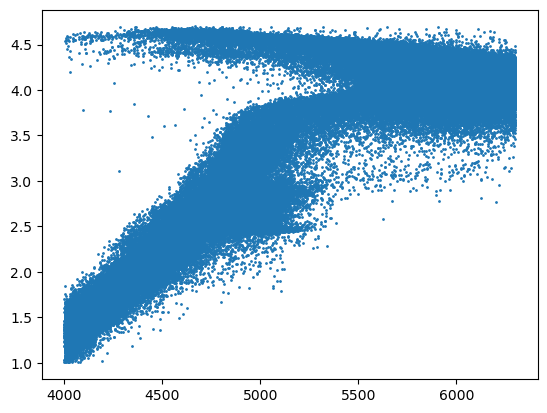

In [42]:
plt.scatter(galah_df.teff, galah_df.logg, s = 1)

In [43]:
galah_sample_dwarfs = galah_df[(galah_df['logg'] > 4.1)  & (galah_df['teff'] > 5000)]
print (f'{len(galah_sample_dwarfs)} dwarf stars')

72299 dwarf stars


In [44]:
galah_sample_giants = galah_df[(galah_df['logg'] < 2.5) & (galah_df['teff'] < 5000)]
print (f'{len(galah_sample_giants)} giant stars')

43753 giant stars


In [45]:
galah_final_sample = pd.merge(galah_sample_dwarfs, galah_sample_giants, how='outer')
print (f'{len(galah_final_sample)} total stars')

116052 total stars


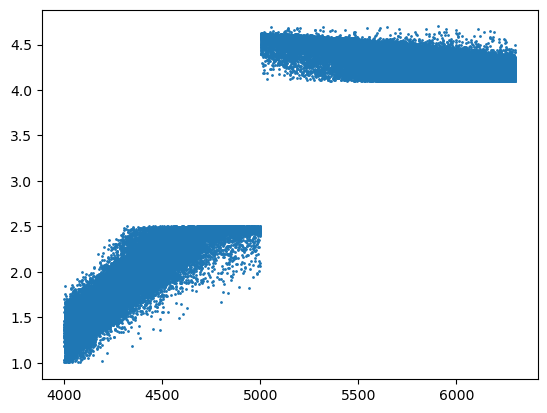

In [46]:
plt.scatter(galah_final_sample.teff, galah_final_sample.logg, s = 1)

In [47]:
galah_final_sample_kin = pd.merge(galah_final_sample, gaia_for_galah_df, on = 'sobject_id', how='inner')
print (f'{len(galah_final_sample_kin)} total stars with kinematics')

116052 total stars with kinematics


In [48]:
kinematic_criteria = (
    (galah_final_sample_kin['parallax'] == galah_final_sample_kin['parallax']) &
    (galah_final_sample_kin['pmra'] == galah_final_sample_kin['pmra']) &
    (galah_final_sample_kin['pmdec'] == galah_final_sample_kin['pmdec'])
)

galah_final_sample_kin = galah_final_sample_kin[kinematic_criteria]
print (f' Galah sample with good kinematics: {len(galah_final_sample_kin)} stars')

 Galah sample with good kinematics: 116050 stars


In [49]:
def calculate_uvw(row):
    UVW_lsr =  UVW(row['ra'], row['dec'], row['pmra'], row['pmdec'], row['rv_comp_1'], row['parallax'])
    return UVW_lsr[0], UVW_lsr[1], UVW_lsr[2] 

# Apply the function to each row using apply with axis=1
galah_final_sample_kin['U_lsr'], galah_final_sample_kin['V_lsr'], galah_final_sample_kin['W_lsr'] = zip(*galah_final_sample_kin.apply(calculate_uvw, axis=1))

In [50]:
# Define a function to apply gal_population to each row
def calculate_probabilities(row):
    probs =  gal_population(row['U_lsr'], row['V_lsr'], row['W_lsr'], char_vel='Mean')
    return probs[0]

# Apply the function to each row using apply with axis=1
galah_final_sample_kin['P_gal'] = galah_final_sample_kin.apply(calculate_probabilities, axis=1)

/home/vadibekyan/Exoplanets/scientific_projects/AI/m_dwarfs/AbundanceML/samples/GalVel_Pop.py:160: RuntimeWarning: invalid value encountered in scalar divide
  Prob[key] = np.round(100 * abs_p[i] / np.sum(abs_p), 1)


In [51]:
# Removing unnesseery columns
galah_final_sample_kin = galah_final_sample_kin.drop(['rv_gaia_dr3', 'e_rv_gaia_dr3', 'snr_px_ccd2', 'flag_sp',
                                                      'flag_fe_h', 'flag_o_fe', 'flag_mg_fe', 'flag_si_fe',
                                                      'ra_error', 'dec_error',  'radial_velocity', 'radial_velocity_error',],axis = 1)

In [52]:
def rounding_to_decimals(df, cols, dec):
    for col in cols:
        df[col] = df[col].apply(lambda x: round(x, dec))
    return df

# Example usage with a list of columns
columns_to_round_to_2_decimals = [
    'rv_comp_1', 'e_rv_comp_1', 'logg', 'e_logg', 'fe_h', 'e_fe_h', 'c_fe', 'e_c_fe', 'o_fe',
    'e_o_fe', 'mg_fe', 'e_mg_fe', 'si_fe', 'e_si_fe', 'c_h', 'e_c_h', 'o_h',
    'e_o_h', 'mg_h', 'e_mg_h', 'si_h', 'e_si_h', 'parallax',
    'parallax_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error',
    'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag', 'r_med_geo',
    'r_med_photogeo', 'U_lsr', 'V_lsr', 'W_lsr',
    ]

columns_to_round_to_0_decimals = ['teff', 'e_teff',]

galah_final_sample_kin = rounding_to_decimals(galah_final_sample_kin, columns_to_round_to_2_decimals, 2)
galah_final_sample_kin = rounding_to_decimals(galah_final_sample_kin, columns_to_round_to_0_decimals, 0)


In [53]:
#galah_final_sample_kin.to_csv('galahDR4_final_sample.csv')

### Selecting best C measurements

In [54]:
carbon_criteria = (
    (galah_final_sample_kin['flag_c_fe'] == 0) &
    (galah_final_sample_kin['c_h'] > -1) & 
    (galah_final_sample_kin['c_h'] < 0.6) & 
    (galah_final_sample_kin['e_c_h'] < 0.1) 
)
galah_final_sample_kin_carbon = galah_final_sample_kin[carbon_criteria]
galah_final_sample_kin_carbon.drop(['flag_c_fe'], axis = 1, inplace = True)
print (f' Galah sample with good carbon abundances: {len(galah_final_sample_kin_carbon)} stars')


 Galah sample with good carbon abundances: 40508 stars


/tmp/ipykernel_15382/2913355757.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  galah_final_sample_kin_carbon.drop(['flag_c_fe'], axis = 1, inplace = True)


In [55]:
#galah_final_sample_kin_carbon.to_csv('galahDR4_final_carbon_sample.csv')

In [65]:
galah_df_copy_dwarf = galah_df_copy[(galah_df_copy['logg'] > 4.0)  & (galah_df_copy['teff'] > 4700)]
galah_df_copy_dwarf[(galah_df_copy_dwarf['flag_n_fe'] == 0)]

,sobject_id,tmass_id,gaiadr3_source_id,survey_name,field_id,setup,mjd,ra,dec,flag_sp,...,parallax_error,ew_li,e_ew_li_low,e_ew_li_upp,a_li,a_li_upp_lim,e_a_li_low,e_a_li_upp,e_a_li_teff,flag_a_li


In [56]:
galah_sample_dwarfs[(galah_sample_dwarfs['flag_o_fe'] == 0)]

,sobject_id,gaiadr3_source_id,rv_comp_1,e_rv_comp_1,rv_gaia_dr3,e_rv_gaia_dr3,snr_px_ccd2,flag_sp,teff,e_teff,...,e_si_fe,flag_si_fe,c_h,e_c_h,o_h,e_o_h,mg_h,e_mg_h,si_h,e_si_h
3,140713004601361,4685221429109310080,24.175571,0.210892,22.977255,0.594025,74.712013,0,5529.029297,68.877304,...,0.015765,0,0.130371,0.065853,0.135678,0.084340,0.179893,0.059382,0.122973,0.058948
5,161118002501226,4976477592542752384,33.268894,0.202934,30.575134,0.938790,95.373833,0,5694.408691,68.380760,...,0.010442,0,0.119479,0.062654,0.059279,0.080901,0.176302,0.058209,0.131125,0.056951
6,200801005101085,4972049927935844480,23.888550,0.205209,24.462076,1.208194,82.290962,0,5856.009277,68.719475,...,0.013211,0,-0.029584,0.068818,0.011328,0.084711,-0.091701,0.064186,-0.020387,0.059862
7,200801005101373,4972259865937767040,-6.209713,0.218900,-5.973836,1.573217,59.996586,0,5971.688965,69.091591,...,0.020722,0,-0.133987,0.103442,-0.007952,0.092946,-0.034322,0.065155,-0.076789,0.062459
11,170711005801103,4900290576426088960,7.417705,0.244395,6.737901,1.970483,56.817028,0,6203.565918,68.716461,...,0.024354,0,-0.197829,0.119050,0.122197,0.080649,-0.027490,0.071815,-0.008586,0.064042
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
917547,170910004101146,2740406528912659328,27.152235,0.203306,26.130600,1.233139,68.694138,0,5217.025879,68.434715,...,0.013493,0,0.322421,0.066926,-0.019378,0.080119,0.446273,0.060096,0.380446,0.059002
917551,200801005101303,6521775347825262080,48.568806,0.215072,48.970814,1.029022,102.343842,0,5783.150391,68.276405,...,0.014399,0,-0.208804,0.080532,-0.000434,0.072761,-0.156789,0.062956,-0.256039,0.060084
917568,140713004601071,6377284715184047488,22.077000,0.205003,20.253916,1.913644,52.111736,0,5851.179199,72.953835,...,0.026223,0,-0.136167,0.113406,-0.035435,0.089539,-0.286556,0.078679,-0.257642,0.070569
917573,140811005001161,6379949244174993408,-1.304426,0.209397,0.951867,1.497392,55.730366,0,6124.162109,69.213020,...,0.021758,0,-0.213119,0.084579,0.042104,0.085693,-0.122449,0.068243,-0.072607,0.063623
